In [1]:
import paulssonlab.deaton.trenchripper.trenchripper as tr

import warnings

warnings.filterwarnings(action="once")

import matplotlib

matplotlib.rcParams["figure.figsize"] = [20, 10]

# addition of active memory manager
import dask
dask.config.set({'distributed.scheduler.active-memory-manager.start': True});
dask.config.set({'distributed.scheduler.worker-ttl': "5m"});
dask.config.set({'distributed.scheduler.allowed-failures': 100});

dask_wd = "/home/lag36/scratch/lag36/dask"

import dask.dataframe as dd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
### QC segmentation
import h5py

In [2]:
dask_controller = tr.trcluster.dask_controller(
    walltime="1:00:00",
    local=False,
    n_workers=20,#200,
    n_workers_min=20,#50,
    memory="2GB", #8GB is good enough
    working_directory=dask_wd
)
dask_controller.startdask()
dask_controller.displaydashboard()

50m
1:00:00


Exception ignored in: <bound method GCDiagnosis._gc_callback of <distributed.utils_perf.GCDiagnosis object at 0x7f4b332f0070>>
Traceback (most recent call last):
  File "/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/distributed/utils_perf.py", line 179, in _gc_callback
    def _gc_callback(self, phase, info):
KeyboardInterrupt: 
Exception ignored in: <bound method GCDiagnosis._gc_callback of <distributed.utils_perf.GCDiagnosis object at 0x7f4b332f0070>>
Traceback (most recent call last):
  File "/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/distributed/utils_perf.py", line 179, in _gc_callback
    def _gc_callback(self, phase, info):
KeyboardInterrupt: 
Exception ignored in: <bound method GCDiagnosis._gc_callback of <distributed.utils_perf.GCDiagnosis object at 0x7f4b332f0070>>
Traceback (most recent call last):
  File "/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/distributed/utils_perf.py", line 179, in _gc_callback
    def _gc

KeyboardInterrupt: 

## Read file and discard bad global rows

Read as parquet and save as csv

In [ ]:
#kymo_df = dd.read_parquet("/home/lag36/scratch/lag36/2022-05-10_AF339-AF339_Ti6_Rapamycin/Growth_Division/kymograph/metadata/",calculate_divisions=True).persist()
#kymo_df.to_csv('/home/lag36/scratch/lag36/2022-05-10_AF339-AF339_Ti6_Rapamycin/Growth_Division/'+'kymo_df_full.csv')

Task exception was never retrieved
future: <Task finished name='Task-35' coro=<_wrap_awaitable() done, defined at /home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/distributed/deploy/spec.py:115> exception=RuntimeError('Command exited with non-zero exit code.\nExit code: -2\nCommand:\nsbatch /tmp/tmpzas__jvo.sh\nstdout:\n\nstderr:\n\n')>
Traceback (most recent call last):
  File "/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/distributed/deploy/spec.py", line 116, in _wrap_awaitable
    return await aw
  File "/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/distributed/deploy/spec.py", line 65, in _
    await self.start()
  File "/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/dask_jobqueue/core.py", line 411, in start
    out = await self._submit_job(fn)
  File "/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/dask_jobqueue/core.py", line 394, in _submit_job
    return self._call(shlex.split(self.submit

Read from the csv file

# Cleanup dataframe

In [3]:
# Read as normal df
df = pd.read_csv('/home/lag36/scratch/lag36/2022-05-10_AF339-AF339_Ti6_Rapamycin/Growth_Division/'+'kymo_df_full.csv').set_index('FOV Parquet Index')

In [4]:
df

,fov,timepoints,trench,time (s),lane orientation,y (local),x (local),y (global),x (global),Global Row,row,File Index,File Trench Index,File Parquet Index,trenchid,Trenchid Timepoint Index
FOV Parquet Index,,,,,,,,,,,,,,,,
1000100000000,1,0,0,0.0,top,82.815200,3.850643,35374.737075,57731.729549,4,1,0,4,40000,4,40000
1000100000001,1,1,0,0.0,top,82.709703,3.850643,35374.428453,57731.651424,4,1,0,4,40001,4,40001
1000100000002,1,2,0,0.0,top,82.604206,3.850643,35374.322956,57731.651424,4,1,0,4,40002,4,40002
1000100000003,1,3,0,0.0,top,82.709703,3.956140,35374.549547,57731.835046,4,1,0,4,40003,4,40003
1000100000004,1,4,0,0.0,top,82.709703,3.850643,35374.350328,57731.729549,4,1,0,4,40004,4,40004
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19000201570896,19,896,157,0.0,bottom,200.655428,530.492020,32667.296053,56958.452958,2,2,463,3,46300030896,5096,50960896
19000201570897,19,897,157,0.0,bottom,200.760926,530.492020,32667.401551,56958.452958,2,2,463,3,46300030897,5096,50960897
19000201570898,19,898,157,0.0,bottom,200.655428,530.492020,32667.296053,56958.531083,2,2,463,3,46300030898,5096,50960898


In [5]:
df.memory_usage(deep=True)

Index                        36321112
fov                          36321112
timepoints                   36321112
trench                       36321112
time (s)                     36321112
lane orientation            279225306
y (local)                    36321112
x (local)                    36321112
y (global)                   36321112
x (global)                   36321112
Global Row                   36321112
row                          36321112
File Index                   36321112
File Trench Index            36321112
File Parquet Index           36321112
trenchid                     36321112
Trenchid Timepoint Index     36321112
dtype: int64

In [6]:
df = (df
 .drop(columns=['time (s)'])
 .astype({'fov': 'int8', 
          'timepoints': 'int16',
          'trench': 'int16',
          'lane orientation': 'category',
          'Global Row': 'int8',
          'row': 'int8',
          'File Index': 'int16',
          'File Trench Index': 'int16', 
          'trenchid': 'int32'})
 # .memory_usage(deep=True)/1e6
)

Text(0.5, 0, 'Global Row Number')

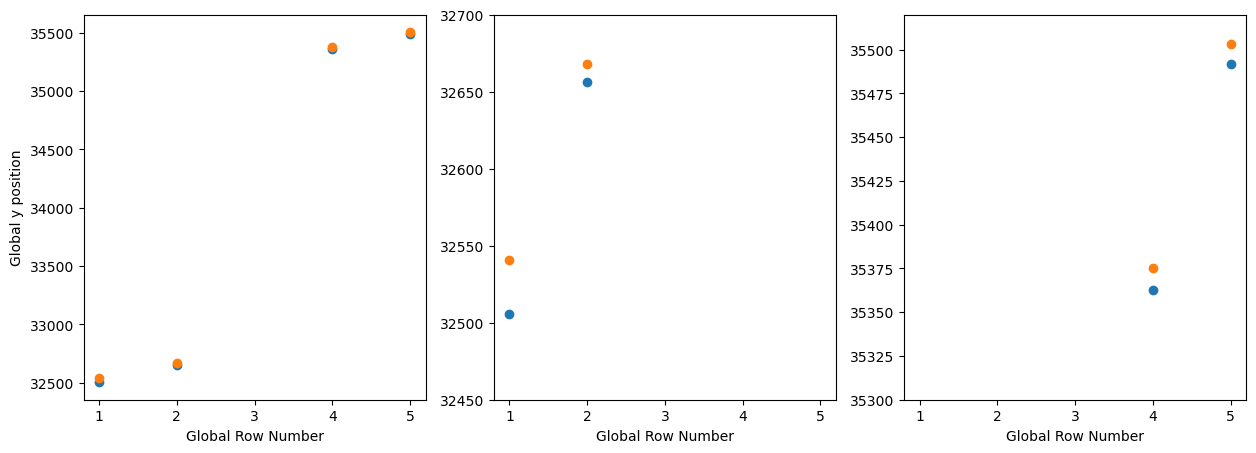

In [9]:
# Get global row inds
global_rows = list(range(6))
mins = []
maxs = []
for i in global_rows:
    df_row_y = df[df['Global Row'] == i]['y (global)']
    mins.append(df_row_y.min())
    maxs.append(df_row_y.max())
    
# Plot global rows positions
fig, axs = plt.subplots(nrows = 1, ncols = 3, figsize=(15,5))
axs[0].scatter(global_rows, mins)
axs[0].scatter(global_rows, maxs)
axs[0].set_xlabel('Global Row Number')
axs[0].set_ylabel('Global y position')

axs[1].scatter(global_rows, mins)
axs[1].scatter(global_rows, maxs)
axs[1].set_ylim(32450, 32700)
axs[1].set_xlabel('Global Row Number')

axs[2].scatter(global_rows, mins)
axs[2].scatter(global_rows, maxs)
axs[2].set_ylim(35300, 35520)
axs[2].set_xlabel('Global Row Number')

I know I should have 2 lines of trenches per FOV, and the fake row corresponding to the number patterns. According to this, rows 0-2 belong to the top FOV row, and rows 3-5 belong to the bottom FOV row. Also, Global rows 0 and 3 are the numbers because they are close to the top trenches, which are then separated by the feeding channel from the bottom trenches (2 and 5).

Now I will check two trenches to look for the IPTG and the Rapamycin patterns

In [10]:
def generate_trench_kymos(channels = ['YFP-DUAL', 'BF'],
                          path_prefix = '/home/lag36/scratch/lag36/2022-05-10_AF339-AF339_Ti6_Rapamycin/Growth_Division/kymograph/kymograph_',
                          file_index = 13,
                          file_trench_index = 2,
                          indices = list(range(0,750,10)),
                          figsize = (10,20),
                          cmap = 'gray'
                         ):
    with h5py.File(path_prefix+str(file_index)+'.hdf5', 'r') as infile: 
        for ch in channels:
            imgs = infile[ch][file_trench_index]
            img = imgs[indices[0]]
            for ind in indices[1:]:
                img_ind = imgs[ind]
                img = np.concatenate((img, img_ind), axis=1)
            plt.figure(figsize=figsize)
            plt.imshow(img, cmap=cmap, aspect=1)
            plt.show()
            plt.close()

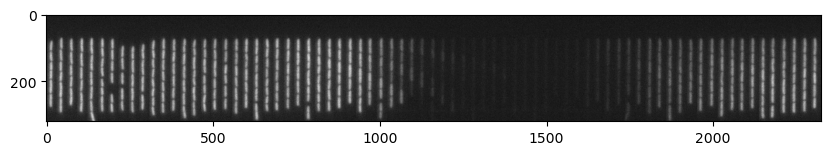

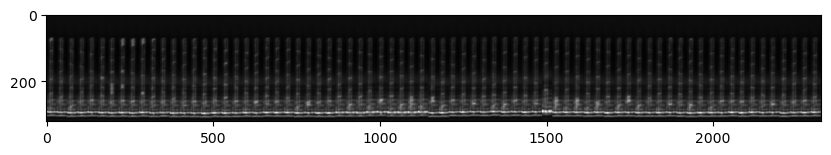

In [11]:
path_prefix_imgs = '/home/lag36/scratch/lag36/2022-05-10_AF339-AF339_Ti6_Rapamycin/Growth_Division/kymograph/kymograph_'
file_index, file_trench_index = 13, 2
indices = list(range(0,750,10))
figsize = (10,20)
generate_trench_kymos(channels = ['YFP-DUAL', 'BF'], path_prefix = path_prefix_imgs,
                      file_index = file_index, file_trench_index = file_trench_index, indices = indices, figsize = figsize, cmap = 'gray')

This trench has the IPTG pattern

In [12]:
df[(df['File Index'] == file_index) & 
        (df['File Trench Index'] == file_trench_index) &
        (df['timepoints'] == 0)
       ]

,fov,timepoints,trench,lane orientation,y (local),x (local),y (global),x (global),Global Row,row,File Index,File Trench Index,File Parquet Index,trenchid,Trenchid Timepoint Index
FOV Parquet Index,,,,,,,,,,,,,,,
1000101410000,1,0,141,top,82.8152,475.422549,35374.737075,58203.301455,4,1,13,2,1300020000,145,1450000


and it is from row 4, so based on this rows 4 and 5 are from the IPTG strain (LAG402 - bAF731).

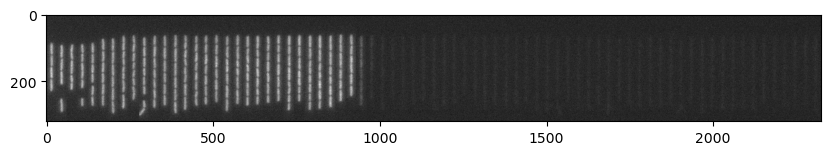

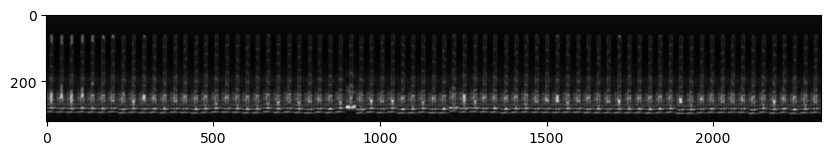

In [13]:
file_index, file_trench_index = 410, 3
indices = list(range(0,750,10))
figsize = (10,20)
generate_trench_kymos(channels = ['YFP-DUAL', 'BF'], path_prefix = '/home/lag36/scratch/lag36/2022-05-10_AF339-AF339_Ti6_Rapamycin/Growth_Division/kymograph/kymograph_',
                      file_index = file_index, file_trench_index = file_trench_index, indices = indices, figsize = figsize, cmap = 'gray')

In [14]:
df[(df['File Index'] == file_index) & 
        (df['File Trench Index'] == file_trench_index) &
        (df['timepoints'] == 0)
       ]

,fov,timepoints,trench,lane orientation,y (local),x (local),y (global),x (global),Global Row,row,File Index,File Trench Index,File Parquet Index,trenchid,Trenchid Timepoint Index
FOV Parquet Index,,,,,,,,,,,,,,,
17000100490000,17,0,49,top,69.628067,168.637068,32536.46791,55296.398786,1,1,410,3,41000030000,4513,45130000


and it is from row 1, so based on this rows 1 and 2 are from the Rapamycin strain (LAG403 - bAF733).

Now let's discard the fake rows and filter out the unloaded trenches. We'll do it based on the presence of fluorescence intensity in YFP on the trench

In [15]:
df[(~df['Global Row'].isin([0,3]))]
df.loc[df['Global Row'].isin([1,2]), 'Inducer'] = 'Rapamycin'
df.loc[df['Global Row'].isin([4,5]), 'Inducer'] = 'IPTG'

df = (df
      .reset_index()
      .set_index(['File Index', 'File Trench Index'])
     )

## Measure YFP 99th percentile fluorescence for everything

In [16]:
channel = 'YFP-DUAL'
file_indices = df.index.get_level_values(0).unique()

for file_index in file_indices:
    with h5py.File(path_prefix_imgs+str(file_index)+'.hdf5', 'r') as infile:

        file_trench_indices = df.loc[df.index.get_level_values(0) == file_index].index.get_level_values(1).unique()
        for file_trench_index in file_trench_indices:
            imgs = infile[channel][file_trench_index]
            YFP_99_file_trench = np.percentile(imgs, 99, axis=(1,2))
            df.loc[(df.index.get_level_values(0) == file_index) & (df.index.get_level_values(1) == file_trench_index), 'YFP 99th Percentile'] = YFP_99_file_trench
    if file_index % 10 == 0:
        print(file_index)

0
10
20
30
40
50
60
70
80
90
100
110
120
130
140
150
160
170
180
190
200
210
220
230
240
250
260
270
280
290
300
310
320
330
340
350
360
370
380
390
400
410
420
430
440
450
460


In [17]:
df.to_pickle('/home/lag36/scratch/lag36/2022-05-10_AF339-AF339_Ti6_Rapamycin/Growth_Division/'+'kymo_df_full_yfp.pkl')

In [18]:
df = pd.read_pickle('/home/lag36/scratch/lag36/2022-05-10_AF339-AF339_Ti6_Rapamycin/Growth_Division/'+'kymo_df_full_yfp.pkl')

## Discard empty trenches - attempt based on trench percentiles of YFP intensity

Get the dataframe with all the first frames per trench

In [19]:
df = (df
      .astype({'Inducer': 'category'})
     )

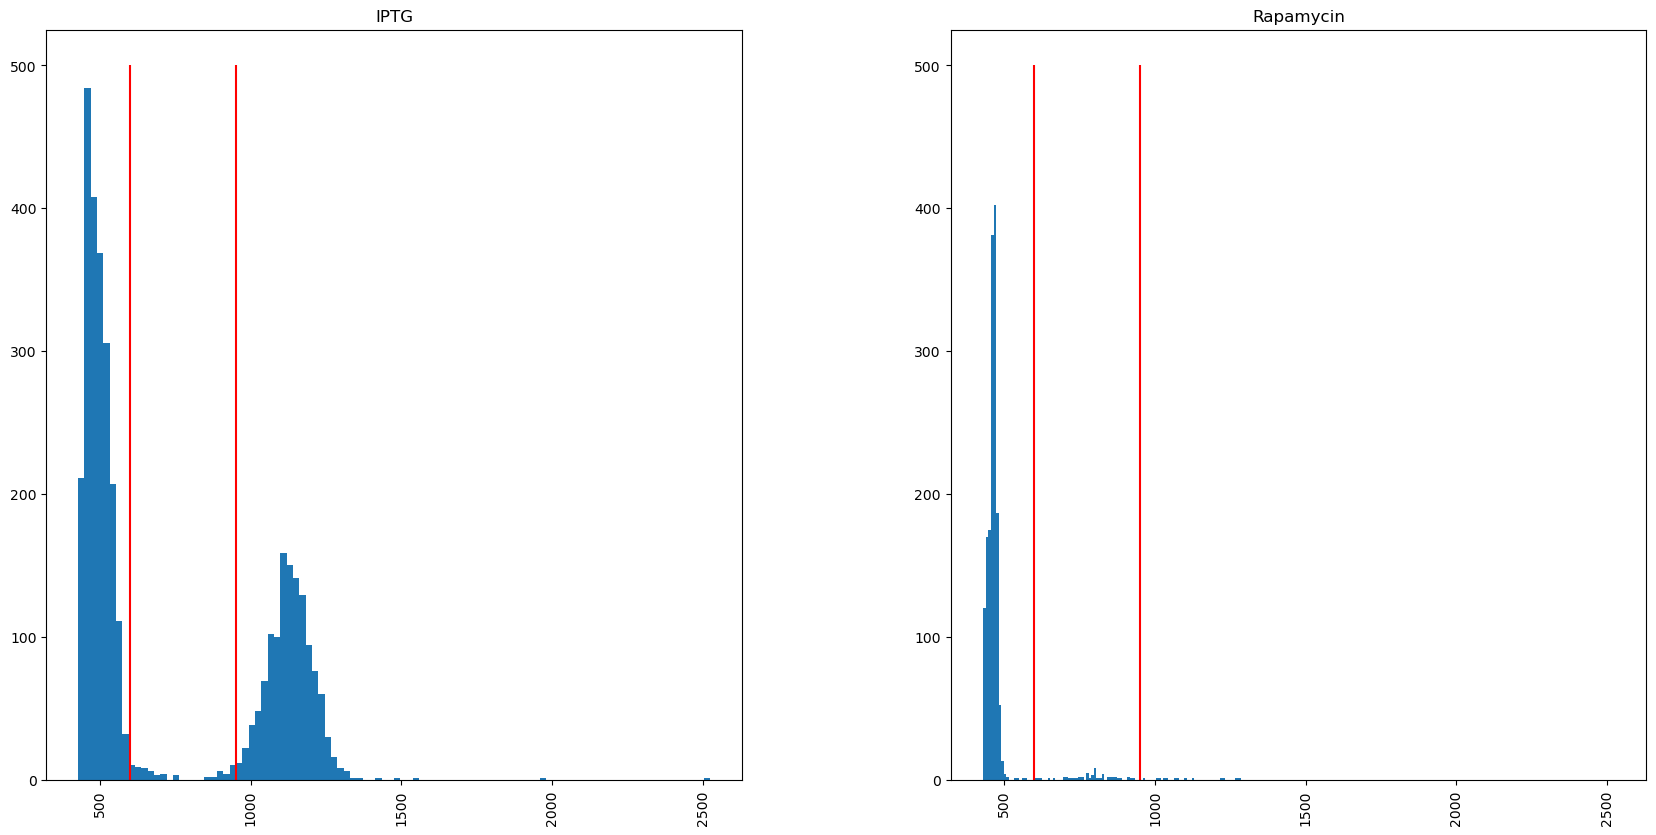

In [20]:
axs = df[df['timepoints'] == 0].hist(column='YFP 99th Percentile', by='Inducer',  bins=100, sharex=True)
lo_cut = 600
hi_cut = 950
axs[0].vlines(lo_cut, 0, 500, 'r')
axs[0].vlines(hi_cut, 0, 500, 'r')

axs[1].vlines(lo_cut, 0, 500, 'r')
axs[1].vlines(hi_cut, 0, 500, 'r')

In [21]:
df

FOV Parquet Index  fov  timepoints  trench  \
File Index File Trench Index                                               
0          4                      1000100000000    1           0       0   
           4                      1000100000001    1           1       0   
           4                      1000100000002    1           2       0   
           4                      1000100000003    1           3       0   
           4                      1000100000004    1           4       0   
...                                         ...  ...         ...     ...   
463        3                     19000201570896   19         896     157   
           3                     19000201570897   19         897     157   
           3                     19000201570898   19         898     157   
           3                     19000201570899   19         899     157   
           3                     19000201570900   19         900     157   

                             lane orientation   y (local)   x (local)  \
File Index File Trench Index                                            
0          4                              top   82.815200    3.850643   
           4                              top   82.709703    3.850643   
           4                              top   82.604206    3.850643   
           4                              top   82.709703    3.956140   
           4                              top   82.709703    3.850643   
...                                       ...         ...         ...   
463        3                           bottom  200.655428  530.492020   
           3                           bottom  200.760926  530.492020   
           3                           bottom  200.655428  530.492020   
           3                           bottom  200.760926  530.386523   
           3                           bottom  200.655428  530.492020   

                                y (global)    x (global)  Global Row  row  \
File Index File Trench Index                                                
0          4                  35374.737075  57731.729549           4    1   
           4                  35374.428453  57731.651424           4    1   
           4                  35374.322956  57731.651424           4    1   
           4                  35374.549547  57731.835046           4    1   
           4                  35374.350328  57731.729549           4    1   
...                                    ...           ...         ...  ...   
463        3                  32667.296053  56958.452958           2    2   
           3                  32667.401551  56958.452958           2    2   
           3                  32667.296053  56958.531083           2    2   
           3                  32667.401551  56958.425585           2    2   
           3                  32667.296053  56958.452958           2    2   

                              File Parquet Index  trenchid  \
File Index File Trench Index                                 
0          4                               40000         4   
           4                               40001         4   
           4                               40002         4   
           4                               40003         4   
           4                               40004         4   
...                                          ...       ...   
463        3                         46300030896      5096   
           3                         46300030897      5096   
           3                         46300030898      5096   
           3                         46300030899      5096   
           3                         46300030900      5096   

                              Trenchid Timepoint Index    Inducer  \
File Index File Trench Index                                        
0          4                                     40000       IPTG   
           4                                     40001       IPTG   
      

In [22]:
df.loc[(df[(df['timepoints'] == 0) & 
          (df['Inducer'] == 'IPTG') & 
          (df['YFP 99th Percentile'] < lo_cut)]
        .index
       ), 'Has Cells'
      ] = False

In [23]:
df.loc[(df[(df['timepoints'] == 0) & 
          (df['Inducer'] == 'IPTG') & 
          (df['YFP 99th Percentile'] > hi_cut)]
        .index
       ), 'Has Cells'
      ] = True

In [24]:
# Remove ambiguous
df = df[~(
    (df['Inducer'] == 'IPTG') & 
    (df['Has Cells'].isna()) 
)]

Split in trench rows (IPTG and Rapamycin)

Hence for the IPTG one I will use these cutoffs but for the Rapamycin ones I won't (also bc for the latter I tested manually and it did not work so well)

## Do a manual lookup for the Rapamycin FOVs

First let's identify the offset between the ND2 files and the pandas table that Daniel's pipeline generates

x: 3599.977, y: 781.630, dx: 14.000, dy: 200.000
x: 3616.000, y: 955.000, dx: 14.000, dy: 200.000
offset_x:-16.02, offset_x::-173.37


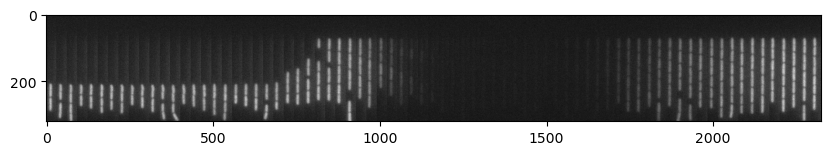

In [25]:
pxl_micron = 0.105951961895293
file_index = 10
file_trench_index = 7

# From pandas table and plot, actual coordinates 
x = 381.424659/pxl_micron
y = 82.8152/pxl_micron
dx = 14 #14
dy = 200
print(f"x: {x:.3f}, y: {y:.3f}, dx: {dx:.3f}, dy: {dy:.3f}")

# From ND2 file, once actual trench was identified
x_r = 3616
y_r = 955

print(f"x: {x_r:.3f}, y: {y_r:.3f}, dx: {dx:.3f}, dy: {dy:.3f}")
offset_y = y-y_r 
offset_x = x-x_r
print(f"offset_x:{offset_x:.2f}, offset_x::{offset_y:.2f}")

indices = list(range(0,750,10))
figsize = (10,20)
generate_trench_kymos(channels = ['YFP-DUAL'], path_prefix = '/home/lag36/scratch/lag36/2022-05-10_AF339-AF339_Ti6_Rapamycin/Growth_Division/kymograph/kymograph_',
                      file_index = file_index, file_trench_index = file_trench_index, indices = indices, figsize = figsize, cmap = 'gray')

Now let's look at each trench with cells in the ND2 file, write the `x` coordinates of the middle of the trench and set the `orientation` accordingly. If I only get one row in the filtered dataframe, I plot it to check that it is actually a trench with cells. If the trenches passes these tests, I append it to a dataframe in the cell below

In [26]:
df_first = df[df['timepoints'] == 0]

1 trenches found
ND2: X=941 pixels
Table: X=924.98, X in (910.98,938.98) pixels
file_idx: 10, file_trench_idx: 7


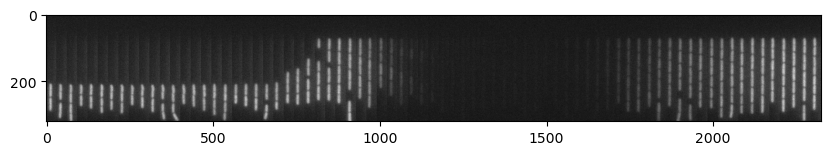

In [27]:
fov = 13
x = 941
# y = 816
orientation = 'bottom'

x_lo = (x+offset_x-dx)*pxl_micron
x_up = (x+offset_x+dx)*pxl_micron
# print(x_lo, x_up)
candidate = df_first[(df_first['fov'] == fov) & (df_first['lane orientation'] == orientation) &
         (df_first['x (local)'] > (x+offset_x-dx)*pxl_micron) & (df_first['x (local)'] < (x+offset_x+dx)*pxl_micron)
        ]

print(f"{len(candidate)} trenches found")
if len(candidate) == 1:
    
    
    file_idx, file_trench_idx = candidate.index[0][0], candidate.index[0][1]
    
    print(f"ND2: X={x} pixels")
    print(f"Table: X={x+offset_x:.2f}, X in ({x+offset_x-dx:.2f},{x+offset_x+dx:.2f}) pixels")
    print(f"file_idx: {file_index}, file_trench_idx: {file_trench_index}")
    
    
    channels = ['YFP-DUAL']#['BF', 'YFP-DUAL']
    generate_trench_kymos(channels = ['YFP-DUAL'], path_prefix = '/home/lag36/scratch/lag36/2022-05-10_AF339-AF339_Ti6_Rapamycin/Growth_Division/kymograph/kymograph_',
                      file_index = file_index, file_trench_index = file_trench_index, indices = indices, figsize = figsize, cmap = 'gray')
# print(candidate)
# candidate.iloc[0]

In [28]:
## Coommented because I already did the manual lookup
# df_winners = pd.concat((df_winners, candidate))
# df_winners.to_csv('/home/lag36/scratch/lag36/2022-05-10_AF339-AF339_Ti6_Rapamycin/Growth_Division/'+'kymo_df_rapa_winners.csv')

## Import the manually chosen Rapamycin trenches

Importing rapamycin trenches and identifying them in the full df

In [29]:
df_winners = (pd.read_csv('/home/lag36/scratch/lag36/2022-05-10_AF339-AF339_Ti6_Rapamycin/Growth_Division/'+'kymo_df_rapa_winners.csv')
              .set_index(['File Index', 'File Trench Index']).sort_index()
             )

FileNotFoundError: [Errno 2] No such file or directory: '/home/lag36/scratch/lag36/2022-05-10_AF339-AF339_Ti6_Rapamycin/Growth_Division/kymo_df_rapa_winners.csv'

In [211]:
df.loc[df_winners.index, 'Has Cells'] = True
df.loc[(df['Inducer'] == 'Rapamycin') & (df['Has Cells'].isna()), 'Has Cells'] = False

In [217]:
df = df.astype({'Has Cells': bool})

In [223]:
df.to_pickle('/home/lag36/scratch/lag36/2022-05-10_AF339-AF339_Ti6_Rapamycin/Growth_Division/'+'kymo_df_full_yfp_classifiedAndFiltered.pkl')

I have all the dataframes for loaded cells in both conditions. I can do better here (incuding more cells, and classifying based on early timepoints, not just on the first one).

Now let's generate the time traces

 I am getting a lot of false positives. I coul

## Get all time series

In [6]:
df = pd.read_pickle('/home/lag36/scratch/lag36/2022-05-10_AF339-AF339_Ti6_Rapamycin/Growth_Division/kymo_df_full_yfp_classifiedAndFiltered.pkl')

In [7]:
df_rapa_no = df[(df['Inducer'] == 'Rapamycin') & (~df['Has Cells'])]
df_rapa_yes = df[(df['Inducer'] == 'Rapamycin') & (df['Has Cells'])]
df_iptg_no = df[(df['Inducer'] == 'IPTG') & (~df['Has Cells'])]
df_iptg_yes = df[(df['Inducer'] == 'IPTG') & (df['Has Cells'])]

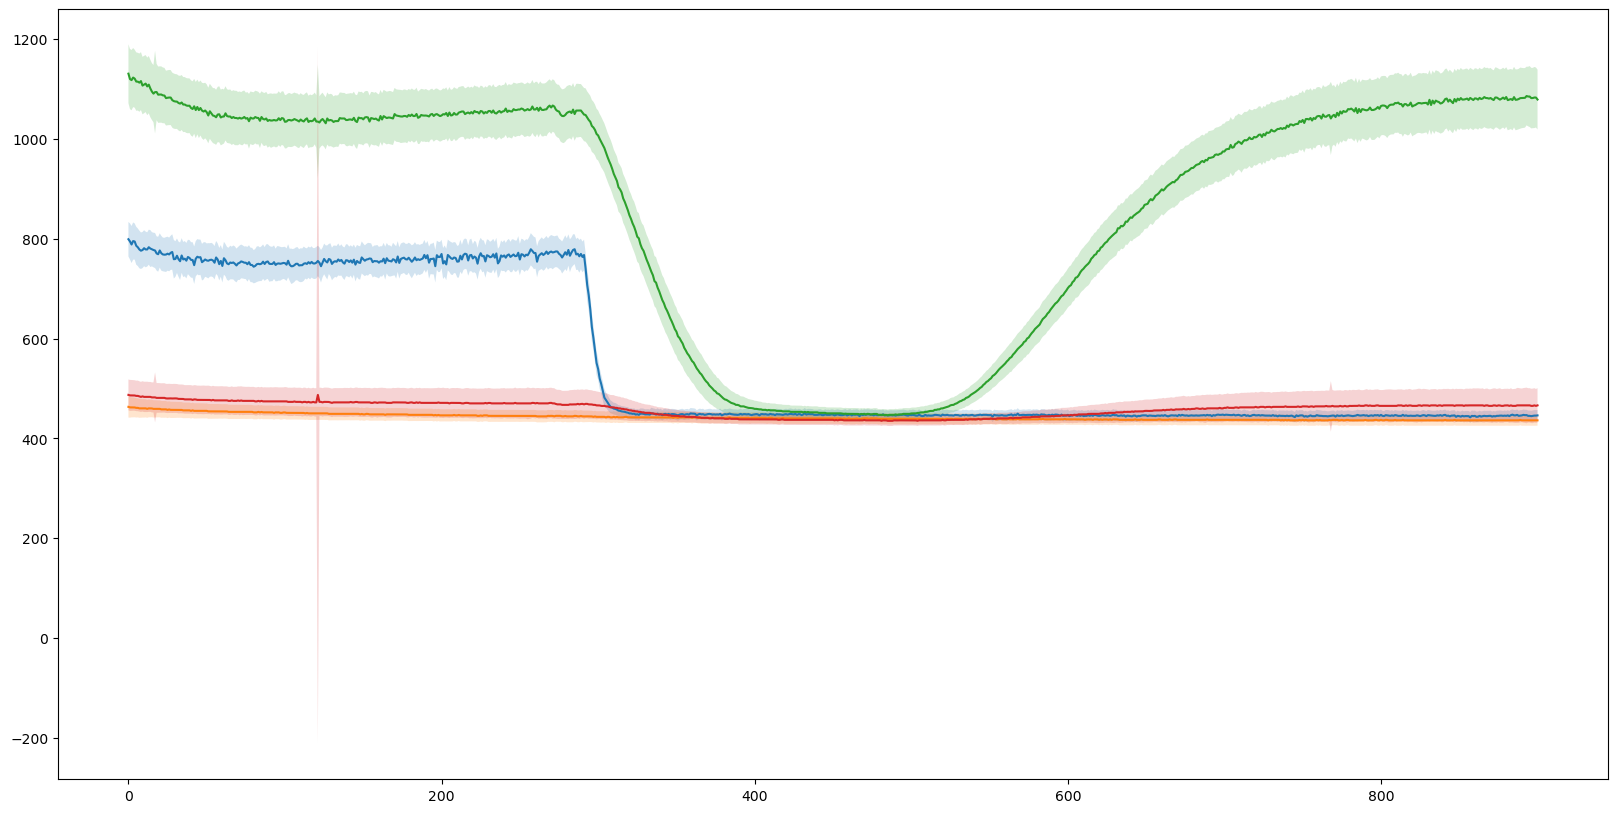

In [8]:
def plot_with_errorbar(df):
    y_med = df.groupby('timepoints')['YFP 99th Percentile'].median()
    y_std = df.groupby('timepoints')['YFP 99th Percentile'].mad()
    x = np.arange(901)
    plt.plot(x, y_med)
    plt.fill_between(x, y_med - y_std, y_med + y_std, alpha = 0.2)
# plt.plot(df_rapa_no.groupby('timepoints')['YFP 99th Percentile'].median())
# plt.plot(df_iptg_yes.groupby('timepoints')['YFP 99th Percentile'].median())
# plt.plot(df_iptg_no.groupby('timepoints')['YFP 99th Percentile'].median())

plot_with_errorbar(df_rapa_yes)
plot_with_errorbar(df_rapa_no)
plot_with_errorbar(df_iptg_yes)
plot_with_errorbar(df_iptg_no)

# Filter the stuff causing the spikes

In [9]:
df = df[~df.index.isin(df[df['YFP 99th Percentile'] > 1600].index)]

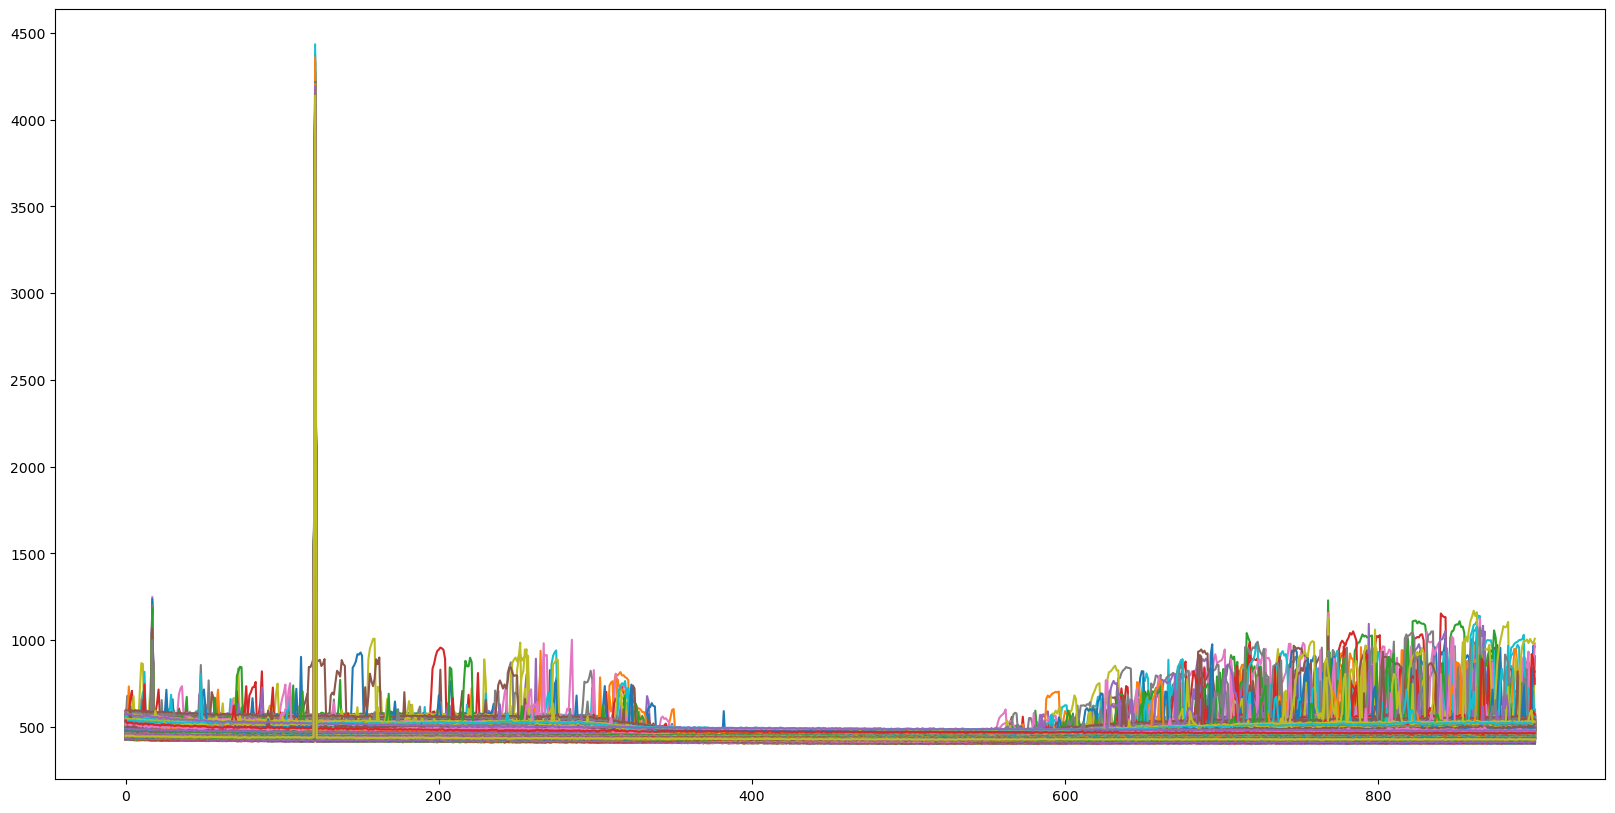

In [10]:
groups = df_iptg_no.groupby(['File Index', 'File Trench Index'])
for _, df_trench in groups:
    # print(df_trench['YFP 99th Percentile'])
    plt.plot(df_trench['YFP 99th Percentile'].values)
    # print(group)
    # break

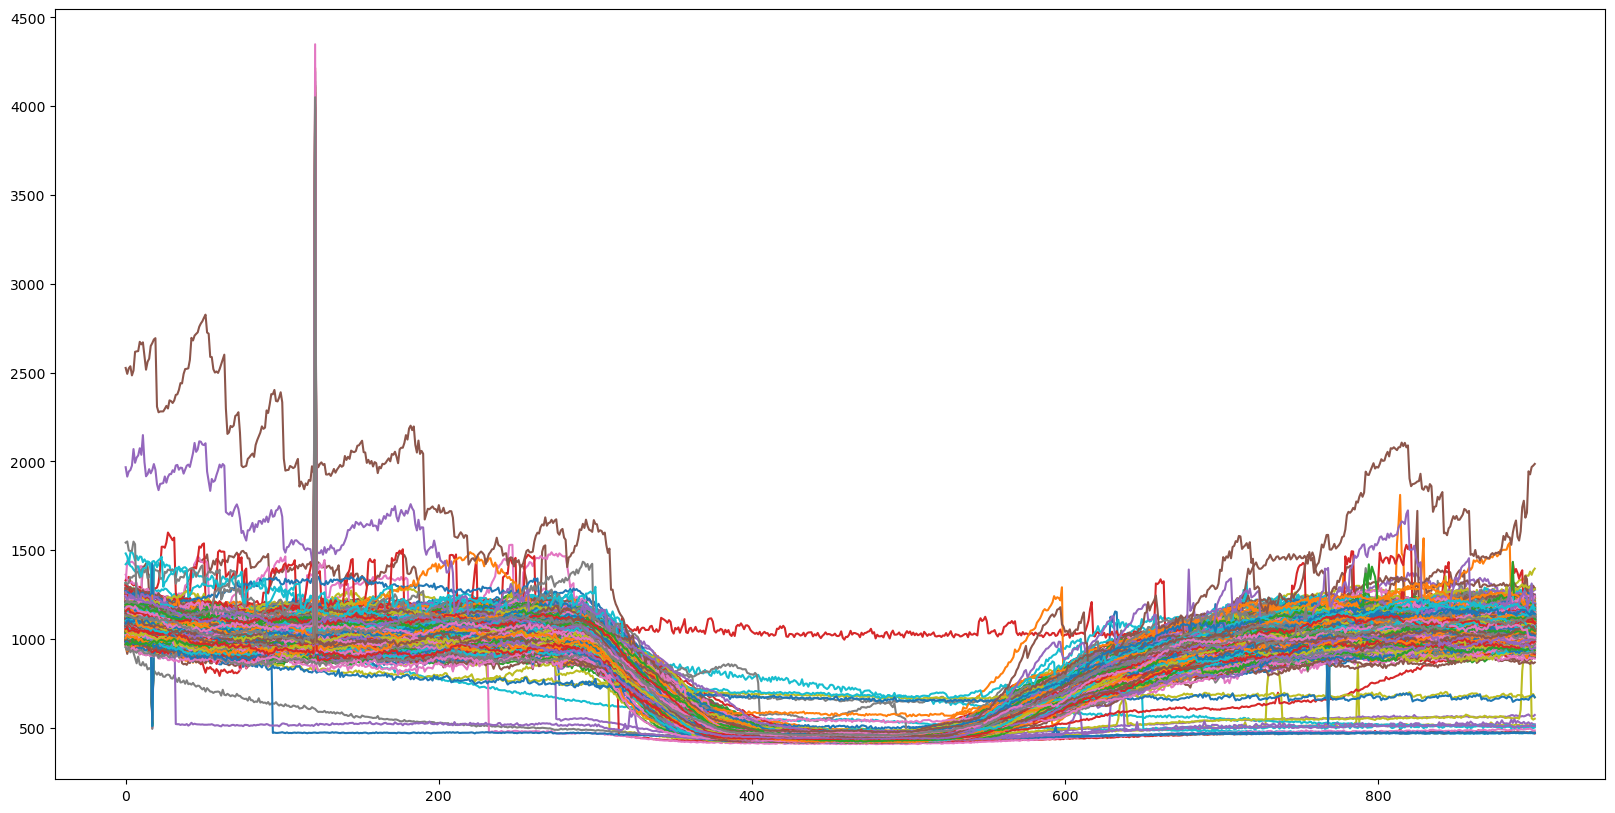

In [11]:
groups = df_iptg_yes.groupby(['File Index', 'File Trench Index'])
for _, df_trench in groups:
    # print(df_trench['YFP 99th Percentile'])
    plt.plot(df_trench['YFP 99th Percentile'].values)
    # print(group)
    # break

## Normalize traces

In [12]:
maxs = df.groupby(['File Index', 'File Trench Index'])['YFP 99th Percentile'].max()
mins = df.groupby(['File Index', 'File Trench Index'])['YFP 99th Percentile'].min()

In [13]:
df['Normalized YFP 99th Percentile'] = (df['YFP 99th Percentile'] - mins) / (maxs - mins)

In [14]:
df_rapa_no = df[(df['Inducer'] == 'Rapamycin') & (~df['Has Cells'])]
df_rapa_yes = df[(df['Inducer'] == 'Rapamycin') & (df['Has Cells'])]
df_iptg_no = df[(df['Inducer'] == 'IPTG') & (~df['Has Cells'])]
df_iptg_yes = df[(df['Inducer'] == 'IPTG') & (df['Has Cells'])]

Text(0.5, 0, 'Time')

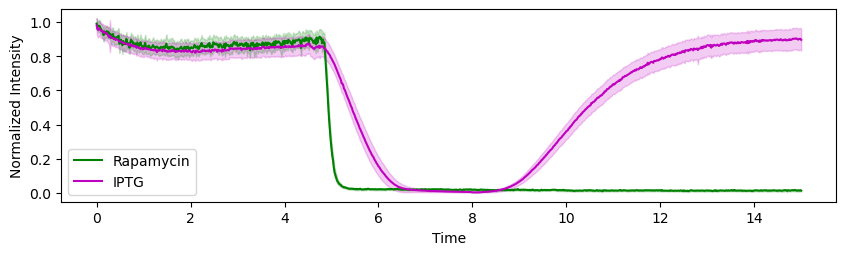

In [15]:
def plot_with_errorbar(df, color='g', alpha = 0.2, label=None):
    y_med = df.groupby('timepoints')['Normalized YFP 99th Percentile'].median()
    y_std = df.groupby('timepoints')['Normalized YFP 99th Percentile'].mad()
    x = np.arange(901)/60
    plt.plot(x, y_med, color = color, label = label)
    plt.fill_between(x, y_med - y_std, y_med + y_std, color= color, alpha = 0.2)
# plt.plot(df_rapa_no.groupby('timepoints')['YFP 99th Percentile'].median())
# plt.plot(df_iptg_yes.groupby('timepoints')['YFP 99th Percentile'].median())
# plt.plot(df_iptg_no.groupby('timepoints')['YFP 99th Percentile'].median())
plt.figure(figsize = (10,2.5))
plot_with_errorbar(df_rapa_yes, color = 'g', label='Rapamycin')
# plot_with_errorbar(df_rapa_no)
plot_with_errorbar(df_iptg_yes, color = 'm', label='IPTG')
# plot_with_errorbar(df_iptg_no)
plt.legend()
plt.ylabel('Normalized Intensity')
plt.xlabel('Time')

# Make figure

- 19:11 (time of the day) - T274 (timepoint) - 4:30:54 (experiment time): I connected the syringe with MBM+ 100 uM IPTG and pushed manually. At T276, ~500 uL had flown through. At T278 ~1mL has flown through
- 19:27 - T290 - 4h49min (experiment time): I connected the syringe with MBM + 5 uM rapamycin and pushed manually. I tried to push harder.
- T293: ~ 1 mL had flown
- T294: ~ 1.2 mL had flown
- T380 (timepoint): I came back and noticed the syringe was depleted, so I connected another syringe with media + IPTG. At ~T380. This media did not warm up, but I did not push manually. I only connected it and flowed at 20 uL/min.
- T389: Connected syringe with media without Rapamycin on the bottom lane. I did this because I found that the syringe was depleted when I came back from dinner. I pushed manually. This media did not warm up.
- T393: ~1mL flown.
- T484: Switched top lane to syringe with media (No IPTG). Started pushing manually.
- T487: I think I pushed 1 mL or more.

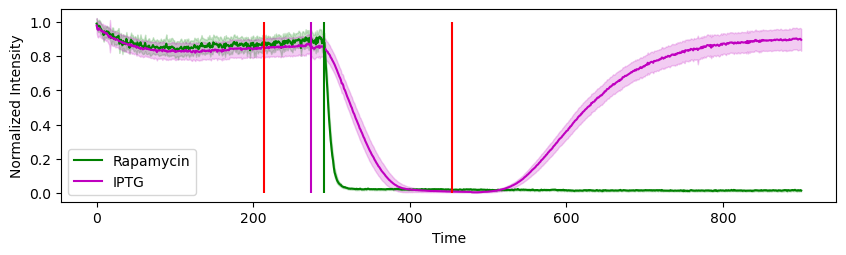

In [17]:
def plot_with_errorbar(df, color='g', alpha = 0.2, label=None):
    y_med = df.groupby('timepoints')['Normalized YFP 99th Percentile'].median()
    y_std = df.groupby('timepoints')['Normalized YFP 99th Percentile'].mad()
    x = np.arange(901)
    plt.plot(x, y_med, color = color, label = label)
    plt.fill_between(x, y_med - y_std, y_med + y_std, color= color, alpha = 0.2)
# plt.plot(df_rapa_no.groupby('timepoints')['YFP 99th Percentile'].median())
# plt.plot(df_iptg_yes.groupby('timepoints')['YFP 99th Percentile'].median())
# plt.plot(df_iptg_no.groupby('timepoints')['YFP 99th Percentile'].median())
plt.figure(figsize = (10,2.5))
plot_with_errorbar(df_rapa_yes, color = 'g', label='Rapamycin')
# plot_with_errorbar(df_rapa_no)
plot_with_errorbar(df_iptg_yes, color = 'm', label='IPTG')
# plot_with_errorbar(df_iptg_no)
plt.legend()
plt.ylabel('Normalized Intensity')
plt.xlabel('Time')
plt.vlines(x=274, ymin=0, ymax=1, color = 'm')
plt.vlines(x=290, ymin=0, ymax=1, color = 'g')
plt.vlines(x=214, ymin=0, ymax=1, color = 'r')
plt.vlines(x=454, ymin=0, ymax=1, color = 'r')
# plt.xlim(

(214.0, 424.0)

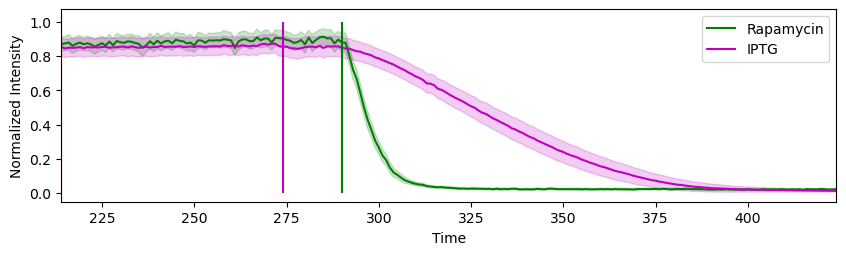

In [18]:
def plot_with_errorbar(df, color='g', alpha = 0.2, label=None):
    y_med = df.groupby('timepoints')['Normalized YFP 99th Percentile'].median()
    y_std = df.groupby('timepoints')['Normalized YFP 99th Percentile'].mad()
    x = np.arange(901)
    plt.plot(x, y_med, color = color, label = label)
    plt.fill_between(x, y_med - y_std, y_med + y_std, color= color, alpha = 0.2)
# plt.plot(df_rapa_no.groupby('timepoints')['YFP 99th Percentile'].median())
# plt.plot(df_iptg_yes.groupby('timepoints')['YFP 99th Percentile'].median())
# plt.plot(df_iptg_no.groupby('timepoints')['YFP 99th Percentile'].median())
plt.figure(figsize = (10,2.5))
plot_with_errorbar(df_rapa_yes, color = 'g', label='Rapamycin')
# plot_with_errorbar(df_rapa_no)
plot_with_errorbar(df_iptg_yes, color = 'm', label='IPTG')
# plot_with_errorbar(df_iptg_no)
plt.legend()
plt.ylabel('Normalized Intensity')
plt.xlabel('Time')
plt.vlines(x=274, ymin=0, ymax=1, color = 'm')
plt.vlines(x=290, ymin=0, ymax=1, color = 'g')
plt.vlines(x=214, ymin=0, ymax=1, color = 'r')
plt.vlines(x=454, ymin=0, ymax=1, color = 'r')
plt.xlim([214,424])

### Offset traces to match the same induction times

In [19]:
df

FOV Parquet Index  fov  timepoints  trench  \
File Index File Trench Index                                               
0          4                      1000100000000    1           0       0   
           4                      1000100000001    1           1       0   
           4                      1000100000002    1           2       0   
           4                      1000100000003    1           3       0   
           4                      1000100000004    1           4       0   
...                                         ...  ...         ...     ...   
463        3                     19000201570896   19         896     157   
           3                     19000201570897   19         897     157   
           3                     19000201570898   19         898     157   
           3                     19000201570899   19         899     157   
           3                     19000201570900   19         900     157   

                             lane orientation   y (local)   x (local)  \
File Index File Trench Index                                            
0          4                              top   82.815200    3.850643   
           4                              top   82.709703    3.850643   
           4                              top   82.604206    3.850643   
           4                              top   82.709703    3.956140   
           4                              top   82.709703    3.850643   
...                                       ...         ...         ...   
463        3                           bottom  200.655428  530.492020   
           3                           bottom  200.760926  530.492020   
           3                           bottom  200.655428  530.492020   
           3                           bottom  200.760926  530.386523   
           3                           bottom  200.655428  530.492020   

                                y (global)    x (global)  Global Row  row  \
File Index File Trench Index                                                
0          4                  35374.737075  57731.729549           4    1   
           4                  35374.428453  57731.651424           4    1   
           4                  35374.322956  57731.651424           4    1   
           4                  35374.549547  57731.835046           4    1   
           4                  35374.350328  57731.729549           4    1   
...                                    ...           ...         ...  ...   
463        3                  32667.296053  56958.452958           2    2   
           3                  32667.401551  56958.452958           2    2   
           3                  32667.296053  56958.531083           2    2   
           3                  32667.401551  56958.425585           2    2   
           3                  32667.296053  56958.452958           2    2   

                              File Parquet Index  trenchid  \
File Index File Trench Index                                 
0          4                               40000         4   
           4                               40001         4   
           4                               40002         4   
           4                               40003         4   
           4                               40004         4   
...                                          ...       ...   
463        3                         46300030896      5096   
           3                         46300030897      5096   
           3                         46300030898      5096   
           3                         46300030899      5096   
           3                         46300030900      5096   

                              Trenchid Timepoint Index    Inducer  \
File Index File Trench Index                                        
0          4                                     40000       IPTG   
           4                                     40001       IPTG   
      

In [20]:
dt_iptg = 274
dt_rapa = 290
df.loc[(df['Inducer'] == 'IPTG'), 'Time Inducer'] = df.loc[(df['Inducer'] == 'IPTG'), 'timepoints'] - dt_iptg
df.loc[(df['Inducer'] == 'Rapamycin'), 'Time Inducer'] = df.loc[(df['Inducer'] == 'Rapamycin'), 'timepoints'] - dt_rapa
df.astype({'Time Inducer': 'int16'})

FOV Parquet Index  fov  timepoints  trench  \
File Index File Trench Index                                               
0          4                      1000100000000    1           0       0   
           4                      1000100000001    1           1       0   
           4                      1000100000002    1           2       0   
           4                      1000100000003    1           3       0   
           4                      1000100000004    1           4       0   
...                                         ...  ...         ...     ...   
463        3                     19000201570896   19         896     157   
           3                     19000201570897   19         897     157   
           3                     19000201570898   19         898     157   
           3                     19000201570899   19         899     157   
           3                     19000201570900   19         900     157   

                             lane orientation   y (local)   x (local)  \
File Index File Trench Index                                            
0          4                              top   82.815200    3.850643   
           4                              top   82.709703    3.850643   
           4                              top   82.604206    3.850643   
           4                              top   82.709703    3.956140   
           4                              top   82.709703    3.850643   
...                                       ...         ...         ...   
463        3                           bottom  200.655428  530.492020   
           3                           bottom  200.760926  530.492020   
           3                           bottom  200.655428  530.492020   
           3                           bottom  200.760926  530.386523   
           3                           bottom  200.655428  530.492020   

                                y (global)    x (global)  Global Row  row  \
File Index File Trench Index                                                
0          4                  35374.737075  57731.729549           4    1   
           4                  35374.428453  57731.651424           4    1   
           4                  35374.322956  57731.651424           4    1   
           4                  35374.549547  57731.835046           4    1   
           4                  35374.350328  57731.729549           4    1   
...                                    ...           ...         ...  ...   
463        3                  32667.296053  56958.452958           2    2   
           3                  32667.401551  56958.452958           2    2   
           3                  32667.296053  56958.531083           2    2   
           3                  32667.401551  56958.425585           2    2   
           3                  32667.296053  56958.452958           2    2   

                              File Parquet Index  trenchid  \
File Index File Trench Index                                 
0          4                               40000         4   
           4                               40001         4   
           4                               40002         4   
           4                               40003         4   
           4                               40004         4   
...                                          ...       ...   
463        3                         46300030896      5096   
           3                         46300030897      5096   
           3                         46300030898      5096   
           3                         46300030899      5096   
           3                         46300030900      5096   

                              Trenchid Timepoint Index    Inducer  \
File Index File Trench Index                                        
0          4                                     40000       IPTG   
           4                                     40001       IPTG   
      

In [21]:
df = df[ (df['Time Inducer'] >= -60) & (df['Time Inducer'] <= 150) ]

In [22]:
df_rapa_no = df[(df['Inducer'] == 'Rapamycin') & (~df['Has Cells'])]
df_rapa_yes = df[(df['Inducer'] == 'Rapamycin') & (df['Has Cells'])]
df_iptg_no = df[(df['Inducer'] == 'IPTG') & (~df['Has Cells'])]
df_iptg_yes = df[(df['Inducer'] == 'IPTG') & (df['Has Cells'])]

In [23]:
def plot_with_errorbar(df, ax, color='g', alpha=0.2, label=None):
    y_med = df.groupby('timepoints')['Normalized YFP 99th Percentile'].median()
    y_std = df.groupby('timepoints')['Normalized YFP 99th Percentile'].mad()
    x = df['Time Inducer'].unique()/60
    ax.plot(x, y_med, color=color, label = label)
    ax.fill_between(x, y_med - y_std, y_med + y_std, color= color, alpha = 0.2)
# plt.plot(df_rapa_no.groupby('timepoints')['YFP 99th Percentile'].median())
# plt.plot(df_iptg_yes.groupby('timepoints')['YFP 99th Percentile'].median())
# plt.plot(df_iptg_no.groupby('timepoints')['YFP 99th Percentile'].median())

In [24]:
plt.figure(figsize = (10,2.5))

plot_with_errorbar(df_rapa_yes, color = 'g', label='Rapamycin')
# plot_with_errorbar(df_rapa_no)
plot_with_errorbar(df_iptg_yes, color = 'm', label='IPTG')
# plot_with_errorbar(df_iptg_no)
plt.legend()
plt.ylabel('Normalized Intensity')
plt.xlabel('Time (hours)')
plt.vlines(x=0, ymin=0, ymax=1, color = 'k', linestyles='--')
# plt.vlines(x=290, ymin=0, ymax=1, color = 'g')
# plt.vlines(x=214, ymin=0, ymax=1, color = 'r')
# plt.vlines(x=454, ymin=0, ymax=1, color = 'r')
plt.xlim([-0.5,2.5])

TypeError: plot_with_errorbar() missing 1 required positional argument: 'ax'

<Figure size 1000x250 with 0 Axes>

In [42]:
def generate_trench_kymos_sub(ax,
                              channels = ['YFP-DUAL'],
                              path_prefix = '/home/lag36/scratch/lag36/2022-05-10_AF339-AF339_Ti6_Rapamycin/Growth_Division/kymograph/kymograph_',
                              file_index = 13,
                              file_trench_index = 2,
                              indices = list(range(0,750,10)),
                              figsize = (10,20),
                              cmap = 'gray'
                         ):
    with h5py.File(path_prefix+str(file_index)+'.hdf5', 'r') as infile: 
        for ch in channels:
            imgs = infile[ch][file_trench_index]
            img = imgs[indices[0]]
            for ind in indices[1:]:
                img_ind = imgs[ind]
                img = np.concatenate((img, img_ind), axis=1)
            # plt.figure(figsize=figsize)
            img = img[50:,:]
        
            print(img.shape)
            ax.imshow(img, cmap=cmap, aspect=1)
            # print(img.shape)
            # plt.show()
            # plt.close()

Image is 270,2356 pxls
Border buffer: Maybe 30 pixels



In [47]:
import matplotlib.patches as patches

10.0

In [49]:
y_buff = 20 #px
x_buff = 20 #px
y_bar = img.shape[0] - y_buff
x_bar = x_buff
rect = patches.Rectangle((x_bar, y_bar), 1/um_per_pixel  , 2)

NameError: name 'img' is not defined

In [44]:
um_per_pixel = 0.105951961895293
pixels_per_um = 1/um_per_pixel

In [45]:
pixels_per_um

9.438239576802266

In [64]:
def draw_size_bar(ax,
                  x_buff = 25,
                  y_buff=30,
                  bar_size_um=5,
                  bar_height_pxl=10):

    y_bar = 270 - y_buff # 270 is the image height
    x_bar = x_buff
    rect = patches.Rectangle((x_bar, y_bar), 5/um_per_pixel, 10, color='w')
    ax.add_patch(rect)

# Final Draft

In [131]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams.update(matplotlib.rcParamsDefault)
%matplotlib inline

(270, 2356)
(270, 2356)


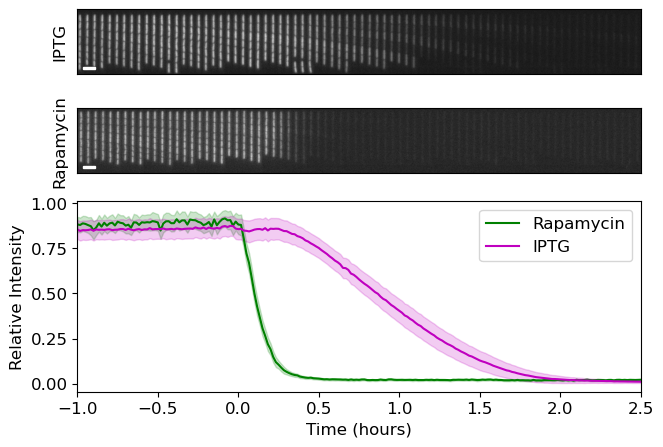

In [141]:
# creating a dictionary
font = {'size': 12}

# using rc function
plt.rc('font', **font)

fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(6,4), gridspec_kw={'height_ratios': [1, 1, 2.5]})

plot_with_errorbar(df_rapa_yes, axs[2], color = 'g', label='Rapamycin')
plot_with_errorbar(df_iptg_yes, axs[2], color = 'm', label='IPTG')

axs[2].set_xlabel('Time (hours)')
axs[2].set_ylabel('Relative Intensity')
axs[2].set_xlim([-1,2.5])
axs[2].legend()
# axs[1].scatter(global_rows, mins)
# axs[1].scatter(global_rows, maxs)
# axs[1].set_ylim(32450, 32700)
# axs[1].set_xlabel('Global Row Number')
path_prefix_imgs = '/home/lag36/scratch/lag36/2022-05-10_AF339-AF339_Ti6_Rapamycin/Growth_Division/kymograph/kymograph_'
file_index, file_trench_index = 13, 2
indices = df['timepoints'].unique()[::3]
figsize = (20,40)
generate_trench_kymos_sub(axs[0], channels = ['YFP-DUAL'], path_prefix = path_prefix_imgs,
                      file_index = file_index, file_trench_index = file_trench_index, indices = indices, figsize = figsize, cmap = 'gray')
# axs[2].scatter(global_rows, mins)
# axs[2].scatter(global_rows, maxs)
# axs[2].set_ylim(35300, 35520)
# axs[2].set_xlabel('Global Row Number')

axs[0].set_xticks([])
axs[0].set_yticks([])
axs[0].set_ylabel('IPTG')

# Draw rectangle
draw_size_bar(axs[0],
              x_buff = 25,
              y_buff=30,
              bar_size_um=5,
              bar_height_pxl=10)

file_index, file_trench_index = 410, 3
indices = df['timepoints'].unique()[::3]
figsize = (10,20)
generate_trench_kymos_sub(axs[1], channels = ['YFP-DUAL'], path_prefix = path_prefix_imgs,
                      file_index = file_index, file_trench_index = file_trench_index, indices = indices, figsize = figsize, cmap = 'gray')

# fig.subplots_adjust(wspace=0.5, left=0.1, right=0.9, top=0.9, bottom=0.3)
axs[1].set_xticks([])
axs[1].set_yticks([])
axs[1].set_ylabel('Rapamycin')

# Draw rectangle
draw_size_bar(axs[1],
              x_buff = 25,
              y_buff=30,
              bar_size_um=5,
              bar_height_pxl=10)

# Arial o Helvetica, 7 pts|
fig.tight_layout(pad=-1, w_pad=1, h_pad=1)
# fig.savefig('draft1.eps', format='eps')
fig.savefig("draft_6x4in.svg", format="svg",transparent=True)

# 8x7

(270, 2356)
(270, 2356)


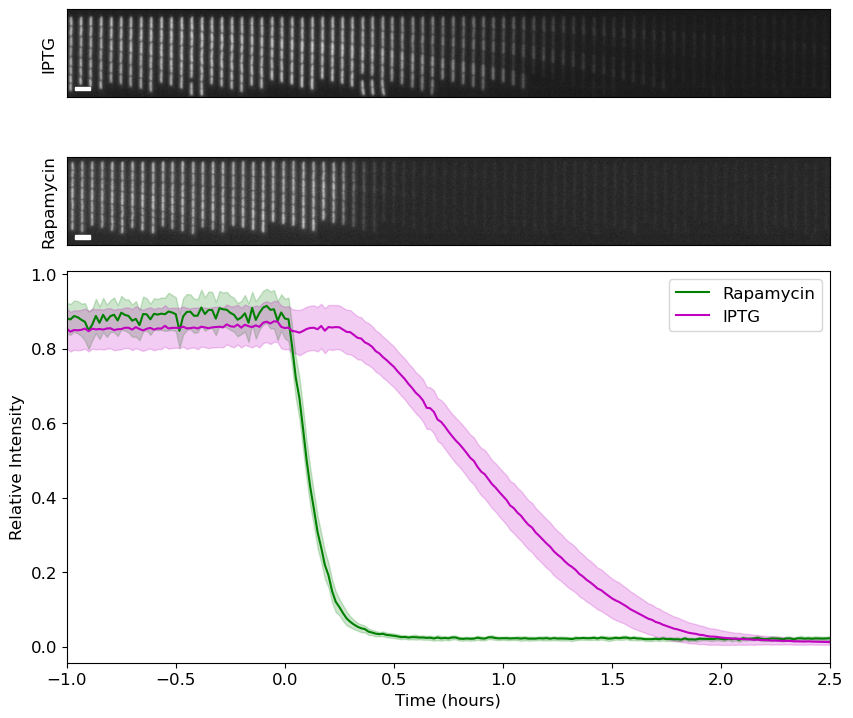

In [142]:
# creating a dictionary
font = {'size': 12}

# using rc function
plt.rc('font', **font)

fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(8,7), gridspec_kw={'height_ratios': [1, 1, 2.5]})

plot_with_errorbar(df_rapa_yes, axs[2], color = 'g', label='Rapamycin')
plot_with_errorbar(df_iptg_yes, axs[2], color = 'm', label='IPTG')

axs[2].set_xlabel('Time (hours)')
axs[2].set_ylabel('Relative Intensity')
axs[2].set_xlim([-1,2.5])
axs[2].legend()
# axs[1].scatter(global_rows, mins)
# axs[1].scatter(global_rows, maxs)
# axs[1].set_ylim(32450, 32700)
# axs[1].set_xlabel('Global Row Number')
path_prefix_imgs = '/home/lag36/scratch/lag36/2022-05-10_AF339-AF339_Ti6_Rapamycin/Growth_Division/kymograph/kymograph_'
file_index, file_trench_index = 13, 2
indices = df['timepoints'].unique()[::3]
figsize = (20,40)
generate_trench_kymos_sub(axs[0], channels = ['YFP-DUAL'], path_prefix = path_prefix_imgs,
                      file_index = file_index, file_trench_index = file_trench_index, indices = indices, figsize = figsize, cmap = 'gray')
# axs[2].scatter(global_rows, mins)
# axs[2].scatter(global_rows, maxs)
# axs[2].set_ylim(35300, 35520)
# axs[2].set_xlabel('Global Row Number')

axs[0].set_xticks([])
axs[0].set_yticks([])
axs[0].set_ylabel('IPTG')

# Draw rectangle
draw_size_bar(axs[0],
              x_buff = 25,
              y_buff=30,
              bar_size_um=5,
              bar_height_pxl=10)

file_index, file_trench_index = 410, 3
indices = df['timepoints'].unique()[::3]
figsize = (10,20)
generate_trench_kymos_sub(axs[1], channels = ['YFP-DUAL'], path_prefix = path_prefix_imgs,
                      file_index = file_index, file_trench_index = file_trench_index, indices = indices, figsize = figsize, cmap = 'gray')

# fig.subplots_adjust(wspace=0.5, left=0.1, right=0.9, top=0.9, bottom=0.3)
axs[1].set_xticks([])
axs[1].set_yticks([])
axs[1].set_ylabel('Rapamycin')

# Draw rectangle
draw_size_bar(axs[1],
              x_buff = 25,
              y_buff=30,
              bar_size_um=5,
              bar_height_pxl=10)

# Arial o Helvetica, 7 pts|
fig.tight_layout(pad=-1, w_pad=-1, h_pad=0)
# fig.savefig('draft1.eps', format='eps')
fig.savefig("draft_8x7in.svg", format="svg",transparent=True)

(270, 2356)
(270, 2356)


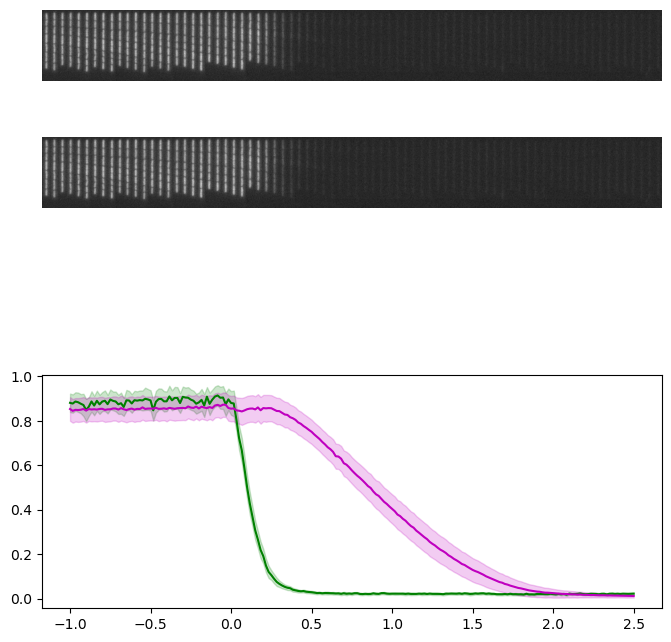

In [102]:
fig = plt.figure(figsize=(8,8))
ax0 = plt.subplot2grid((5,1), (0,0), rowspan=1)
ax1 = plt.subplot2grid((5,1), (1,0), rowspan=1)
ax2 = plt.subplot2grid((5,1), (3,0), rowspan=2)

plot_with_errorbar(df_rapa_yes, ax2, color = 'g', label='Rapamycin')
plot_with_errorbar(df_iptg_yes, ax2, color = 'm', label='IPTG')

ax0.autoscale_view('tight')
ax0.set_axis_off()
generate_trench_kymos_sub(ax0, channels = ['YFP-DUAL'], path_prefix = path_prefix_imgs,
                      file_index = file_index, file_trench_index = file_trench_index, indices = indices, figsize = figsize, cmap = 'gray')

ax1.autoscale_view('tight')
ax1.set_axis_off()
generate_trench_kymos_sub(ax1, channels = ['YFP-DUAL'], path_prefix = path_prefix_imgs,
                      file_index = file_index, file_trench_index = file_trench_index, indices = indices, figsize = figsize, cmap = 'gray')

# plt.subplots_adjust(left=0, bottom=0, right=1, top=1, wspace=1, hspace=0.3)

In [ ]:
fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(8,8), gridspec_kw={'height_ratios': [1, 1, 2]})




plot_with_errorbar(df_rapa_yes, axs[2], color = 'g', label='Rapamycin')
plot_with_errorbar(df_iptg_yes, axs[2], color = 'm', label='IPTG')

axs[2].set_xlabel('Time (hours)')
axs[2].set_ylabel('Relative\n Intensity')
axs[2].set_xlim([-1,2.5])
axs[2].legend()
# axs[1].scatter(global_rows, mins)
# axs[1].scatter(global_rows, maxs)
# axs[1].set_ylim(32450, 32700)
# axs[1].set_xlabel('Global Row Number')
path_prefix_imgs = '/home/lag36/scratch/lag36/2022-05-10_AF339-AF339_Ti6_Rapamycin/Growth_Division/kymograph/kymograph_'
file_index, file_trench_index = 13, 2
indices = df['timepoints'].unique()[::3]
figsize = (20,40)
generate_trench_kymos_sub(axs[0], channels = ['YFP-DUAL'], path_prefix = path_prefix_imgs,
                      file_index = file_index, file_trench_index = file_trench_index, indices = indices, figsize = figsize, cmap = 'gray')
# axs[2].scatter(global_rows, mins)
# axs[2].scatter(global_rows, maxs)
# axs[2].set_ylim(35300, 35520)
# axs[2].set_xlabel('Global Row Number')

axs[0].set_xticks([])
axs[0].set_yticks([])
axs[0].set_ylabel('IPTG')

# Draw rectangle
draw_size_bar(axs[0],
              x_buff = 25,
              y_buff=30,
              bar_size_um=5,
              bar_height_pxl=10)

file_index, file_trench_index = 410, 3
indices = df['timepoints'].unique()[::3]
figsize = (10,20)
generate_trench_kymos_sub(axs[1], channels = ['YFP-DUAL'], path_prefix = path_prefix_imgs,
                      file_index = file_index, file_trench_index = file_trench_index, indices = indices, figsize = figsize, cmap = 'gray')

# fig.subplots_adjust(wspace=0.5, left=0.1, right=0.9, top=0.9, bottom=0.3)
axs[1].set_xticks([])
axs[1].set_yticks([])
axs[1].set_ylabel('Rapamycin')

# Draw rectangle
draw_size_bar(axs[1],
              x_buff = 25,
              y_buff=30,
              bar_size_um=5,
              bar_height_pxl=10)

# Arial o Helvetica, 7 pts|
fig.tight_layout(pad=-1, w_pad=-1, h_pad=-1)

# End

(270, 2356)
(270, 2356)


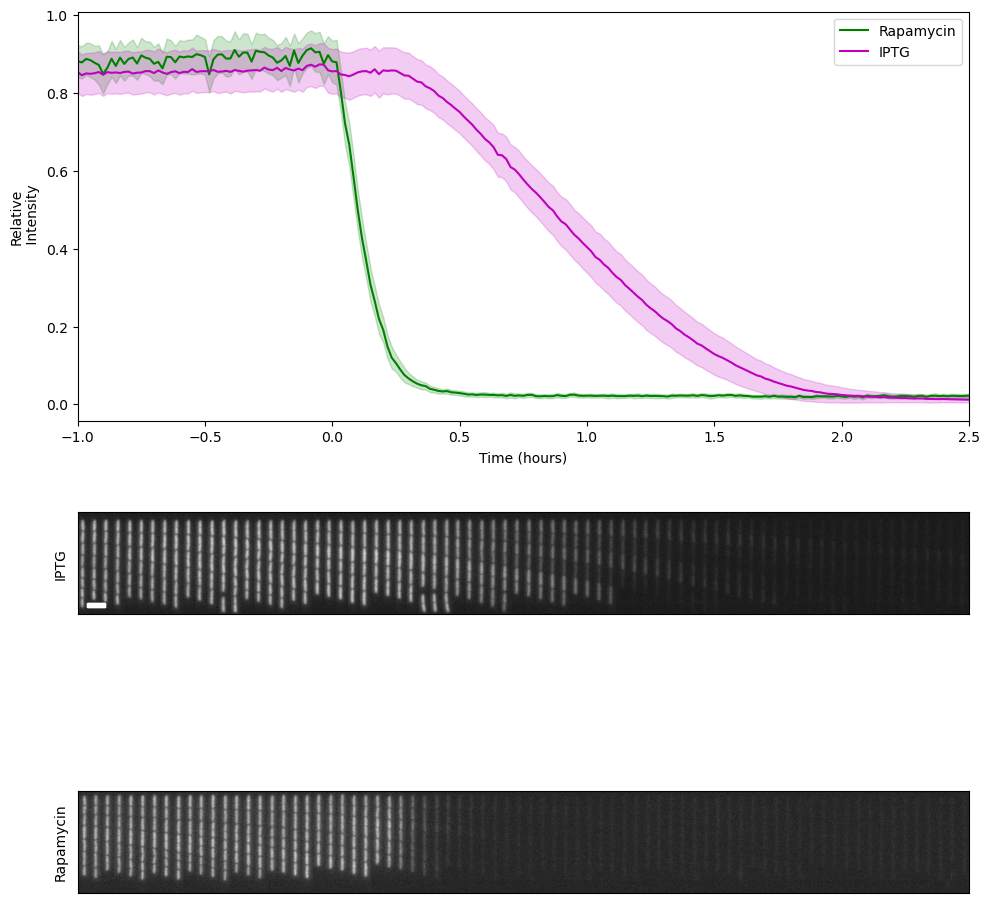

In [66]:
fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(10,10), gridspec_kw={'height_ratios': [1.5, 1, 1]})

plot_with_errorbar(df_rapa_yes, axs[0], color = 'g', label='Rapamycin')
plot_with_errorbar(df_iptg_yes, axs[0], color = 'm', label='IPTG')

axs[0].set_xlabel('Time (hours)')
axs[0].set_ylabel('Relative\n Intensity')
axs[0].set_xlim([-1,2.5])
axs[0].legend()
# axs[1].scatter(global_rows, mins)
# axs[1].scatter(global_rows, maxs)
# axs[1].set_ylim(32450, 32700)
# axs[1].set_xlabel('Global Row Number')
path_prefix_imgs = '/home/lag36/scratch/lag36/2022-05-10_AF339-AF339_Ti6_Rapamycin/Growth_Division/kymograph/kymograph_'
file_index, file_trench_index = 13, 2
indices = df['timepoints'].unique()[::3]
figsize = (20,40)
generate_trench_kymos_sub(axs[1], channels = ['YFP-DUAL'], path_prefix = path_prefix_imgs,
                      file_index = file_index, file_trench_index = file_trench_index, indices = indices, figsize = figsize, cmap = 'gray')
# axs[2].scatter(global_rows, mins)
# axs[2].scatter(global_rows, maxs)
# axs[2].set_ylim(35300, 35520)
# axs[2].set_xlabel('Global Row Number')

axs[1].set_xticks([])
axs[1].set_yticks([])
axs[1].set_ylabel('IPTG')

# Draw rectangle
draw_size_bar(axs[1],
              x_buff = 25,
              y_buff=30,
              bar_size_um=5,
              bar_height_pxl=10)

file_index, file_trench_index = 410, 3
indices = df['timepoints'].unique()[::3]
figsize = (10,20)
generate_trench_kymos_sub(axs[2], channels = ['YFP-DUAL'], path_prefix = path_prefix_imgs,
                      file_index = file_index, file_trench_index = file_trench_index, indices = indices, figsize = figsize, cmap = 'gray')

# fig.subplots_adjust(wspace=0.5, left=0.1, right=0.9, top=0.9, bottom=0.3)
axs[2].set_xticks([])
axs[2].set_yticks([])
axs[2].set_ylabel('Rapamycin')

# Draw rectangle
draw_size_bar(axs[1],
              x_buff = 25,
              y_buff=30,
              bar_size_um=5,
              bar_height_pxl=10)

# Arial o Helvetica, 7 pts
# plt.tight_layout()

Text(0, 0.5, 'Rapamycin')

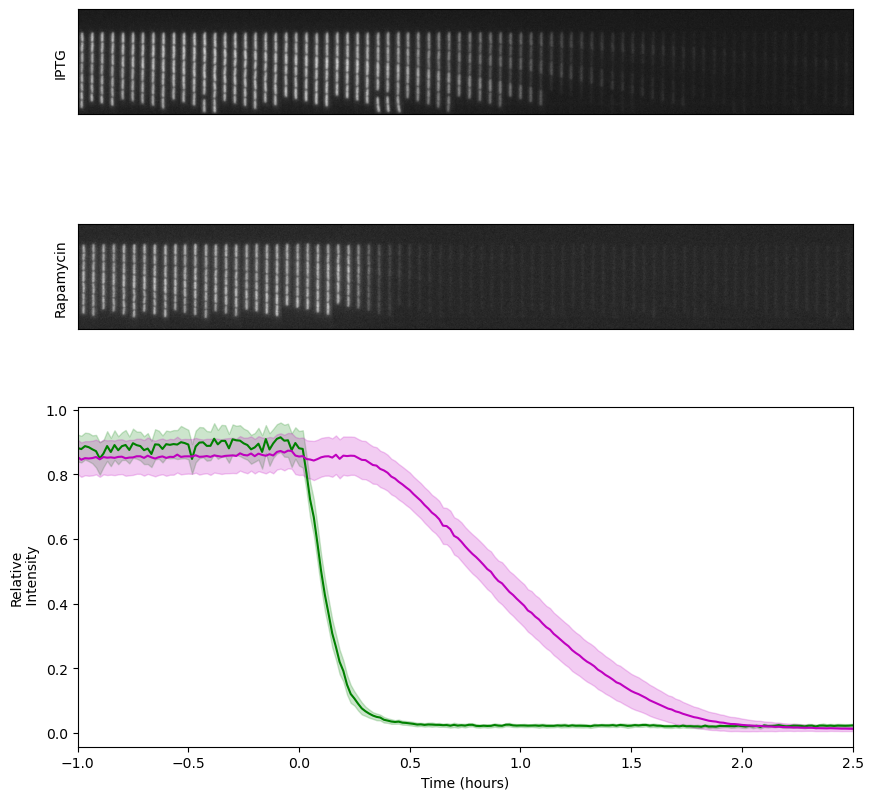

In [29]:
fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(10,10), gridspec_kw={'height_ratios': [1, 1, 2]})

plot_with_errorbar(df_rapa_yes, axs[2], color = 'g', label='Rapamycin')
plot_with_errorbar(df_iptg_yes, axs[2], color = 'm', label='IPTG')

axs[2].set_xlabel('Time (hours)')
axs[2].set_ylabel('Relative\n Intensity')
axs[2].set_xlim([-1,2.5])
# fig.tight_layout()
# axs[1].scatter(global_rows, mins)
# axs[1].scatter(global_rows, maxs)
# axs[1].set_ylim(32450, 32700)
# axs[1].set_xlabel('Global Row Number')
path_prefix_imgs = '/home/lag36/scratch/lag36/2022-05-10_AF339-AF339_Ti6_Rapamycin/Growth_Division/kymograph/kymograph_'
file_index, file_trench_index = 13, 2
indices = df['timepoints'].unique()[::3]
figsize = (20,40)
generate_trench_kymos_sub(axs[0], channels = ['YFP-DUAL'], path_prefix = path_prefix_imgs,
                      file_index = file_index, file_trench_index = file_trench_index, indices = indices, figsize = figsize, cmap = 'gray')
# axs[2].scatter(global_rows, mins)
# axs[2].scatter(global_rows, maxs)
# axs[2].set_ylim(35300, 35520)
# axs[2].set_xlabel('Global Row Number')

axs[0].set_xticks([])
axs[0].set_yticks([])
axs[0].set_ylabel('IPTG')

file_index, file_trench_index = 410, 3
indices = df['timepoints'].unique()[::3]
figsize = (10,20)
generate_trench_kymos_sub(axs[1], channels = ['YFP-DUAL'], path_prefix = path_prefix_imgs,
                      file_index = file_index, file_trench_index = file_trench_index, indices = indices, figsize = figsize, cmap = 'gray')

# fig.subplots_adjust(wspace=0.5, left=0.1, right=0.9, top=0.9, bottom=0.3)
axs[1].set_xticks([])
axs[1].set_yticks([])
axs[1].set_ylabel('Rapamycin')

In [ ]:
ax.set_xticks([])

In [ ]:
path_prefix_imgs = '/home/lag36/scratch/lag36/2022-05-10_AF339-AF339_Ti6_Rapamycin/Growth_Division/kymograph/kymograph_'
file_index, file_trench_index = 13, 2
indices = df['timepoints'].unique()[::3]
figsize = (10,20)
generate_trench_kymos(channels = ['YFP-DUAL', 'BF'], path_prefix = path_prefix_imgs,
                      file_index = file_index, file_trench_index = file_trench_index, indices = indices, figsize = figsize, cmap = 'gray')

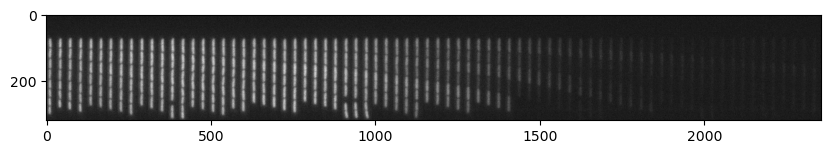

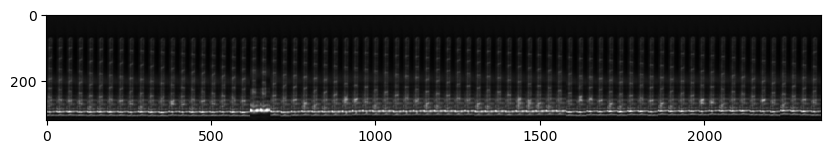

In [83]:
path_prefix_imgs = '/home/lag36/scratch/lag36/2022-05-10_AF339-AF339_Ti6_Rapamycin/Growth_Division/kymograph/kymograph_'
file_index, file_trench_index = 13, 2
indices = df['timepoints'].unique()[::3]
figsize = (10,20)
generate_trench_kymos(channels = ['YFP-DUAL', 'BF'], path_prefix = path_prefix_imgs,
                      file_index = file_index, file_trench_index = file_trench_index, indices = indices, figsize = figsize, cmap = 'gray')


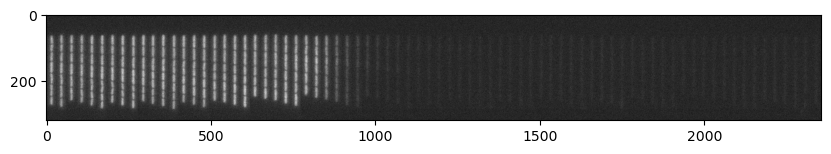

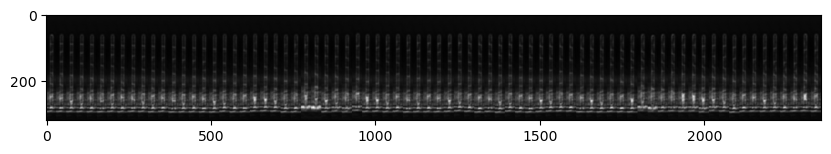

In [77]:
path_prefix_imgs = '/home/lag36/scratch/lag36/2022-05-10_AF339-AF339_Ti6_Rapamycin/Growth_Division/kymograph/kymograph_'
file_index, file_trench_index = 410, 3
indices = df['timepoints'].unique()[::3]
figsize = (10,20)
generate_trench_kymos(channels = ['YFP-DUAL', 'BF'], path_prefix = path_prefix_imgs,
                      file_index = file_index, file_trench_index = file_trench_index, indices = indices, figsize = figsize, cmap = 'gray')

In [81]:
print(1)

1


In [74]:
df['timepoints'].unique()[::2]

array([214, 216, 218, 220, 222, 224, 226, 228, 230, 232, 234, 236, 238,
       240, 242, 244, 246, 248, 250, 252, 254, 256, 258, 260, 262, 264,
       266, 268, 270, 272, 274, 276, 278, 280, 282, 284, 286, 288, 290,
       292, 294, 296, 298, 300, 302, 304, 306, 308, 310, 312, 314, 316,
       318, 320, 322, 324, 326, 328, 330, 332, 334, 336, 338, 340, 342,
       344, 346, 348, 350, 352, 354, 356, 358, 360, 362, 364, 366, 368,
       370, 372, 374, 376, 378, 380, 382, 384, 386, 388, 390, 392, 394,
       396, 398, 400, 402, 404, 406, 408, 410, 412, 414, 416, 418, 420,
       422, 424, 426, 428, 430, 432, 434, 436, 438, 440], dtype=int16)

In [67]:
df['timepoints'].unique()

array([214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226,
       227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239,
       240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 251, 252,
       253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265,
       266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278,
       279, 280, 281, 282, 283, 284, 285, 286, 287, 288, 289, 290, 291,
       292, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304,
       305, 306, 307, 308, 309, 310, 311, 312, 313, 314, 315, 316, 317,
       318, 319, 320, 321, 322, 323, 324, 325, 326, 327, 328, 329, 330,
       331, 332, 333, 334, 335, 336, 337, 338, 339, 340, 341, 342, 343,
       344, 345, 346, 347, 348, 349, 350, 351, 352, 353, 354, 355, 356,
       357, 358, 359, 360, 361, 362, 363, 364, 365, 366, 367, 368, 369,
       370, 371, 372, 373, 374, 375, 376, 377, 378, 379, 380, 381, 382,
       383, 384, 385, 386, 387, 388, 389, 390, 391, 392, 393, 39

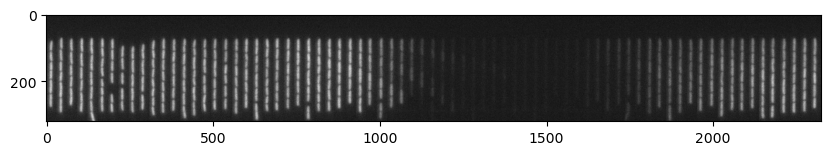

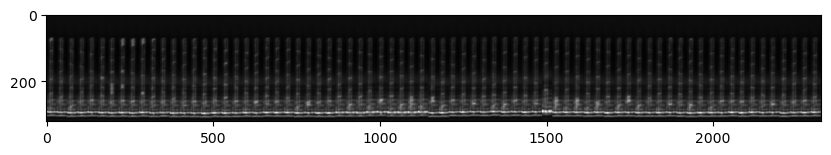

In [66]:
path_prefix_imgs = '/home/lag36/scratch/lag36/2022-05-10_AF339-AF339_Ti6_Rapamycin/Growth_Division/kymograph/kymograph_'
file_index, file_trench_index = 13, 2
indices = list(range(0,750,10))
figsize = (10,20)
generate_trench_kymos(channels = ['YFP-DUAL', 'BF'], path_prefix = path_prefix_imgs,
                      file_index = file_index, file_trench_index = file_trench_index, indices = indices, figsize = figsize, cmap = 'gray')

# TODO: 
- Cleanup notebook (variable names, sections)
- Perform normalization per trace, then average. That should avoid all errors (??). 
- Do it for all the IPTG ones
- Make a nice figure:
    - Plot with all traces
    - x axis in hours 
    - Zoom in the decay process
    - No increase
    
## OPTIONAL
- Do Flat Field correction (or correlate with position)
- Do experiment with FK drug!??, more throughput?


- Nucleoids. Get ready for nb2
- This notebook. Continue
- Probability class
- Terminal class
- Python class
- Review R stuff